# 04 · Average word length

**Do openings with shorter words win more often?** Use the same published training pairs, randomized A/B assignments, and three OP-discussion-grouped folds as the other linguistic feature notebooks.

After Minimal cleaning, count alphabetic characters per word token and average over occurrences. For example, “don't go go” has eight letters across three tokens. Repetitions count, apostrophes add no letters, and the shared tokenizer splits hyphenated words. Each opening's word count comes from the shared pair assignments, matching P2's length feature.

The [standalone script](analyze_average_word_length.py) saves timestamped runs. To regenerate, use the same environment as the word-frequency notebook, including `wordfreq==3.1.1` for the shared loader, and keep its saved content-word Zipf scores available.

In [1]:
import json
from pathlib import Path
import subprocess
import sys

import numpy as np
import pandas as pd
from IPython.display import display

REPO = next(
    p for p in (Path.cwd(), *Path.cwd().parents)
    if (p / "team-setup").is_dir() and (p / "pyproject.toml").is_file()
)
RUNS = REPO / "project/data/processed/linguistic-features/average-word-length"
SCRIPT = REPO / "project/notebooks/linguistic-features/lexical-complexity/analyze_average_word_length.py"
RUN_ID = None
runs = sorted(RUNS.glob("*/results.json"))
if RUN_ID is None and not runs:
    subprocess.run([sys.executable, str(SCRIPT)], check=True)
    runs = sorted(RUNS.glob("*/results.json"))
report_path = RUNS / RUN_ID / "results.json" if RUN_ID else runs[-1]
report = json.loads(report_path.read_text())
pairs = pd.read_parquet(report_path.parent / "paired_scores.parquet")
openings = pd.read_parquet(report_path.parent / "opening_scores.parquet")
print(f"{len(pairs):,} complete pairs · {len(openings):,} unique openings · {report['discussions']:,} discussions")

3,451 complete pairs · 6,581 unique openings · 2,507 discussions


## Distribution and examples

Count each distinct opening once. Inspect examples at both tails. Very short openings and specialized vocabulary can make the extremes easier to reach.

In [2]:
feature = "average_word_length"
display(openings[[feature, "measured_tokens"]].describe(
    percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]
).round(3))
examples = pd.concat({
    "Shortest words": openings.nsmallest(3, feature),
    "Longest words": openings.nlargest(3, feature),
})
display(examples[[feature, "measured_tokens", "opening_preview"]].round(3))

,average_word_length,measured_tokens
count,6581.000,6581.000
mean,4.521,234.739
std,0.309,193.381
min,3.570,40.000
1%,3.845,51.000
25%,4.310,107.000
50%,4.507,176.000
75%,4.722,296.000
99%,5.289,987.400
max,5.909,1724.000


average_word_length  measured_tokens                                                                                                                                                                                                                                   opening_preview
               comment_id                                                                                                                                                                                                                                                                                        
Shortest words t1_c9qhay7                3.570              100  It's become a cliche at this point, but I believe that I can be absolutely 100% sure without an inkling of a doubt that I exist. I'm not saying I know what I am, who I am, what it is that it means to exist. But whatever it is, I do it, and 
               t1_cfgdo8i                3.607               56  It makes the road too unpredictable. Let's say that I want to turn right onto a single-lane road. I look left, and see that there is a car coming, but it is far away, so I go. If the other driver was going 100 MPH instead of the 50 I was pr
               t1_cmzx0i4                3.611               95  Do you think that the fact that most of these men and women expressing these views are young comes into play? I think most Redditors are between 14-25 and that is the age where all you want to do is have fun, so the idea of having a child i
Longest words  t1_cdhpzkr                5.909               55  Heteronormative and nonheteronormative are subsets of typical and atypical, respectively. Something that is heteronormative is always typical, but not everything that is typical is heteronormative. Wearing shoes is typical, but it is not he
               t1_cd9eqz1                5.837              184  Solar radiation. Abstract from "Solar radiation and human health" by Juzeniene et al. "The Sun has played a major role in the development of life on Earth. In Western culture, people are warned against Sun exposure because of its adverse ef
               t1_cpjq913                5.762              105  Technically speaking, someone with antisocial personality disorder (sociopaths and psychopaths) does not (possibly cannot) feel lonely. I would suggest that your observations have been of individuals with bipolar disorder, borderline person

## Paired association and standalone prediction

Report how often the opening with shorter average words received the delta, among unequal-score pairs. Bootstrap the 95% interval by OP discussion. Repeat within pairs whose overall opening word counts differ by at most 50 words.

The standalone model predicts whether side A won from the signed A-minus-B difference in average word length, with standardization inside each training fold. ROC-AUC is the primary metric and A-wins prevalence is the reference for average precision.

In [3]:
metrics = pd.DataFrame({
    "All pairs": report["winner_shorter"], "Within 50 words": report["within_50_words"],
}).T.rename(columns={"winner_higher": "Winner shorter", "winner_lower": "Winner longer"})
metrics["Winner shorter (%)"] = 100 * metrics["winner_higher_rate"].astype(float)
metrics["95% CI lower (%)"] = metrics["ci_95"].map(lambda interval: 100 * interval[0])
metrics["95% CI upper (%)"] = metrics["ci_95"].map(lambda interval: 100 * interval[1])
display(metrics[[
    "pairs", "Winner shorter", "Winner longer", "ties",
    "Winner shorter (%)", "95% CI lower (%)", "95% CI upper (%)",
]].infer_objects().round(3))
display(pd.Series({
    "ROC-AUC": report["prediction"]["roc_auc"],
    "Average precision": report["prediction"]["average_precision"],
    "A-wins prevalence": report["prediction"]["a_win_prevalence"],
}, name="Value").round(4).to_frame())

,pairs,Winner shorter,Winner longer,ties,Winner shorter (%),95% CI lower (%),95% CI upper (%)
All pairs,3451,1605,1845,1,46.522,44.675,48.265
Within 50 words,1144,558,585,1,48.819,45.826,51.778


,Value
ROC-AUC,0.5522
Average precision,0.5368
A-wins prevalence,0.4967


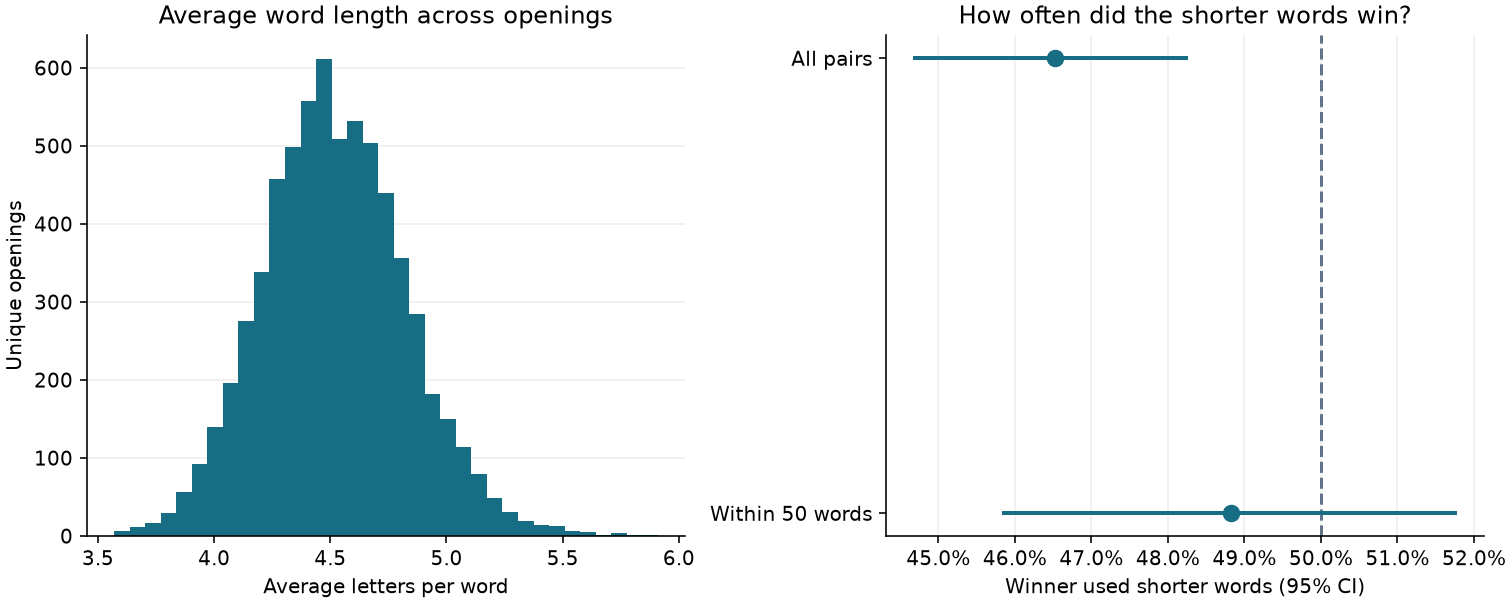

In [4]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

fig, (distribution, paired_plot) = plt.subplots(1, 2, figsize=(10.5, 4.2), layout="constrained")
distribution.hist(openings[feature], bins=35, color="#176d83")
distribution.set(title="Average word length across openings",
                 xlabel="Average letters per word", ylabel="Unique openings")
rows = np.arange(len(metrics))
paired_plot.axvline(50, linestyle="--", color="#63748a", label="50%")
paired_plot.hlines(rows, metrics["95% CI lower (%)"], metrics["95% CI upper (%)"], color="#176d83", lw=2)
paired_plot.scatter(metrics["Winner shorter (%)"], rows, color="#176d83", s=60, zorder=3)
paired_plot.set_yticks(rows, metrics.index.tolist())
paired_plot.invert_yaxis()
paired_plot.set(title="How often did the shorter words win?",
                xlabel="Winner used shorter words (95% CI)")
paired_plot.xaxis.set_major_formatter(PercentFormatter(100))
for ax, axis in ((distribution, "y"), (paired_plot, "x")):
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis=axis, alpha=0.22)
    ax.set_axisbelow(True)
plt.show()

## Correlations with P2 inputs

Pearson measures linear association and Spearman measures monotonic association. Distinct openings describe the features across replies. Signed A-minus-B differences show how the features relate in the form used by the paired models. Both correlations in each row use the cases with all three features available.

In [5]:
labels = {
    "average_word_length": "Average word length",
    "word_count": "Opening word count",
    "mean_content_word_zipf": "Mean content-word Zipf",
}
pair_features = pairs[[f"a_minus_b_{feature}" for feature in labels]].copy()
pair_features.columns = list(labels)
correlations = []
for unit, frame in {"Unique openings": openings, "A-minus-B pair differences": pair_features}.items():
    features = frame[list(labels)].dropna()
    pearson = features.corr(method="pearson")
    spearman = features.corr(method="spearman")
    for baseline in ("word_count", "mean_content_word_zipf"):
        correlations.append({
            "Unit": unit, "Compared with": labels[baseline], "Observations": len(features),
            "Pearson": pearson.loc[feature, baseline], "Spearman": spearman.loc[feature, baseline],
        })
display(pd.DataFrame(correlations).set_index(["Unit", "Compared with"]).round(4))

Observations  Pearson  Spearman
Unit                       Compared with                                          
Unique openings            Opening word count              6581   0.0110    0.0185
                           Mean content-word Zipf          6581  -0.5702   -0.5675
A-minus-B pair differences Opening word count              3451  -0.0040   -0.0132
                           Mean content-word Zipf          3451  -0.5905   -0.5740